# ✦ E-commerce Sales Analysis with Python ✦

Practice project using **pandas**, **matplotlib** and **seaborn** on an e-commerce dataset with four sheets (Orders, Returns, People, Archive).

**Flow:** load all sheets → clean → explore orders → visualise → box plots and outliers (bonus).

> Place `Ecommerce_Sales_Practice_Dataset.xlsx` in the `data/` folder before running.

In [2]:
#1. Import the required libraries:

In [3]:
import pandas as pd

In [4]:
import matplotlib.pyplot as plt


In [5]:
import seaborn as sns

In [6]:
#Read the Excel file containing multiple

In [7]:
file= pd.read_excel("../data/Ecommerce_Sales_Practice_Dataset.xlsx",sheet_name=None)

In [8]:
#Display all available sheet names.


In [9]:
file.keys()

dict_keys(['Orders', 'Returns', 'People', 'Archive'])

In [10]:
#Remove the unnecessary Archive sheet.


In [11]:
del file['Archive']

In [12]:
file

{'Orders':      Order_ID              Order_Date Customer_ID   City         Category  \
 0    ORD-0001 2025-01-01 00:00:00.000    CUST-024  Cairo  Office Supplies   
 1    ORD-0002 2025-01-02 12:33:08.285    CUST-067  Aswan        Furniture   
 2    ORD-0003 2025-01-04 01:06:16.569    CUST-021  Aswan          Fashion   
 3    ORD-0004 2025-01-05 13:39:24.854    CUST-064  Cairo  Office Supplies   
 4    ORD-0005 2025-01-07 02:12:33.138    CUST-038  Tanta      Electronics   
 ..        ...                     ...         ...    ...              ...   
 238  ORD-0239 2025-12-29 11:26:51.715    CUST-019  Aswan      Electronics   
 239  ORD-0240 2025-12-31 00:00:00.000    CUST-048   Giza      Electronics   
 240  ORD-0008 2025-01-11 15:51:57.992    CUST-043  Cairo  Office Supplies   
 241  ORD-0032 2025-02-17 05:07:16.820    CUST-060  Cairo          Fashion   
 242  ORD-0090 2025-05-16 13:09:17.322    CUST-046  Aswan  Office Supplies   
 
     Sub-Category         Segment  Quantity    Sales

In [13]:
#Use a for loop to iterate through all DataFrames --
#Remove duplicate records from each DataFrame using drop_duplicates()


In [14]:
for sheet_name, df in file.items():
  df.drop_duplicates(inplace=True)

In [15]:
returns= file['Returns']

In [16]:
people= file['People']

In [17]:
orders= file['Orders']

In [18]:
#Explore the Orders DataFrame using info().


In [19]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
Index: 240 entries, 0 to 239
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Order_ID      240 non-null    object        
 1   Order_Date    240 non-null    datetime64[ns]
 2   Customer_ID   240 non-null    object        
 3   City          240 non-null    object        
 4   Category      240 non-null    object        
 5   Sub-Category  240 non-null    object        
 6   Segment       240 non-null    object        
 7   Quantity      240 non-null    int64         
 8   Sales         240 non-null    float64       
 9   Profit        240 non-null    float64       
dtypes: datetime64[ns](1), float64(2), int64(1), object(6)
memory usage: 20.6+ KB


In [20]:
#Part 2: Data Analysis
#Using the Orders DataFrame:

In [21]:
#1. Calculate the number of orders in each Category using value_counts().


In [22]:
N_category= orders['Category'].value_counts()

In [23]:
N_category

,count
Category,
Office Supplies,74
Electronics,68
Furniture,55
Fashion,43


In [24]:
#Identify the most frequently ordered Sub-Category.

In [25]:
N_SUC= orders['Sub-Category'].value_counts()

In [26]:
N_SUC

,count
Sub-Category,
Pens,24
Phones,22
Accessories,18
Labels,18
Tables,17
Laptops,16
Binders,16
Paper,16
Storage,16


In [27]:
N_SUC.idxmax()

'Pens'

In [28]:
#3. Analyze the distribution of customers across different Segments.

In [29]:
SEG= orders['Segment'].value_counts()

In [30]:
SEG

,count
Segment,
Consumer,129
Corporate,63
Small Business,48


In [31]:
#4. Explore the Quantity column and understand its distribution.

In [32]:
orders['Quantity'].describe()

,Quantity
count,240.000000
mean,5.329167
std,2.861515
min,1.000000
25%,3.000000
50%,5.000000
75%,8.000000
max,10.000000


In [33]:
orders['Quantity'].value_counts()

,count
Quantity,
4,28
5,27
2,26
1,25
8,25
3,24
10,22
6,22
9,22


In [34]:
## Part 3: Data Visualization

In [35]:
#1. *Line Plot:* Visualize the number of orders across different Categories.

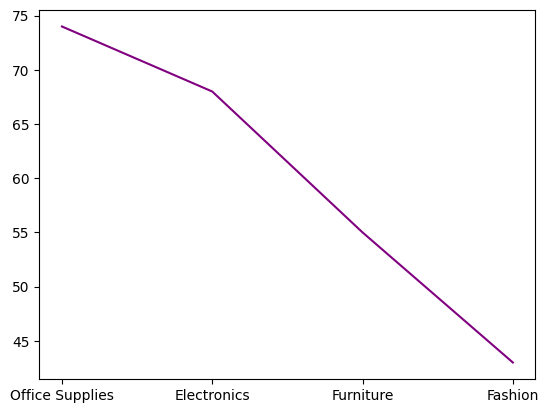

In [36]:
plt.plot(N_category,"purple")

In [37]:
#2. *Bar Chart:* Compare the number of orders across different Sub-Categories.

Text(0, 0.5, 'Orders')

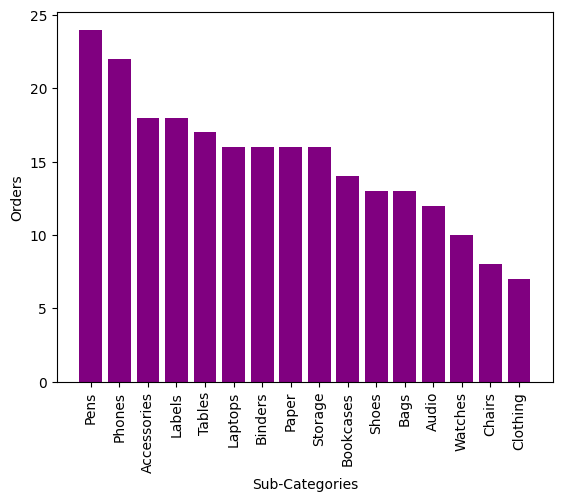

In [38]:
plt.bar(N_SUC.index,N_SUC.values,color="purple")
plt.xticks(rotation=90)
plt.xlabel("Sub-Categories")
plt.ylabel("Orders")

In [39]:
#3. *Pie Chart:* Show the percentage distribution of customers across different Segments.

Text(0.5, 1.0, 'Customer Distribution by Segment')

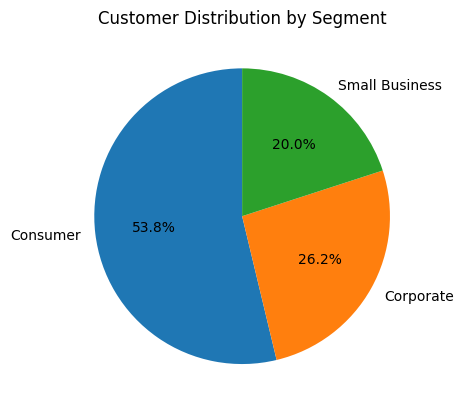

In [40]:
plt.pie(SEG,startangle=90,
        autopct='%1.1f%%'
        ,labels=SEG.index)
plt.title('Customer Distribution by Segment')

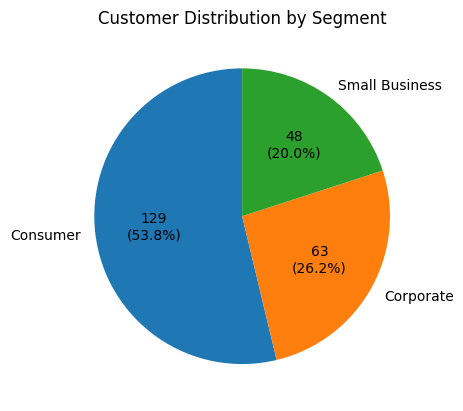

In [41]:
total = SEG.sum()

def make_label(pct):
    count = round(pct * total / 100)
    return f'{count}\n({pct:.1f}%)'

plt.pie(SEG, labels=SEG.index, autopct=make_label, startangle=90)
plt.title('Customer Distribution by Segment')
plt.show()

In [42]:
#4. *Histogram:* Visualize the distribution of Quantity.

<Axes: xlabel='Quantity', ylabel='Count'>

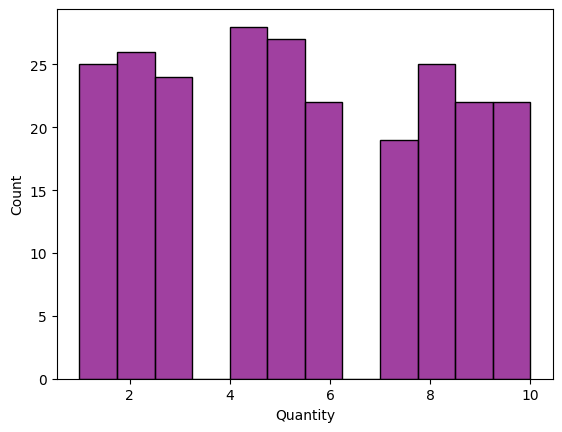

In [43]:
sns.histplot(orders['Quantity'],bins=12,color="purple")

In [44]:
#5. Seaborn Bar Plot:* Compare the average Quantity across different Categories.

/tmp/ipykernel_7614/1326093830.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Category",y="Quantity",data=orders,palette="rocket")


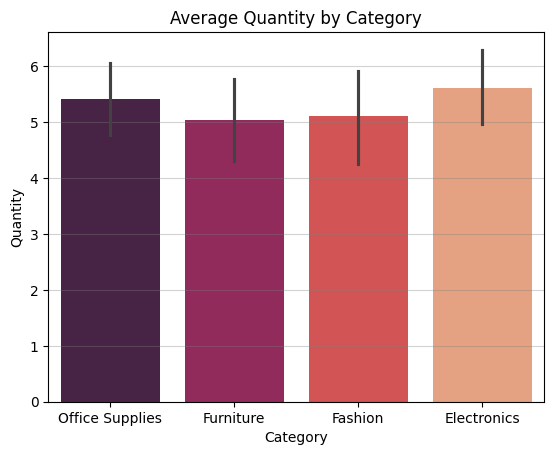

In [45]:
sns.barplot(x="Category",y="Quantity",data=orders,palette="rocket")
plt.title('Average Quantity by Category')
plt.grid(axis="y",color="gray",alpha=0.35)

In [46]:
#6. *Scatter Plot:* Explore the relationship between Sales and Profit.

<Axes: xlabel='Sales', ylabel='Profit'>

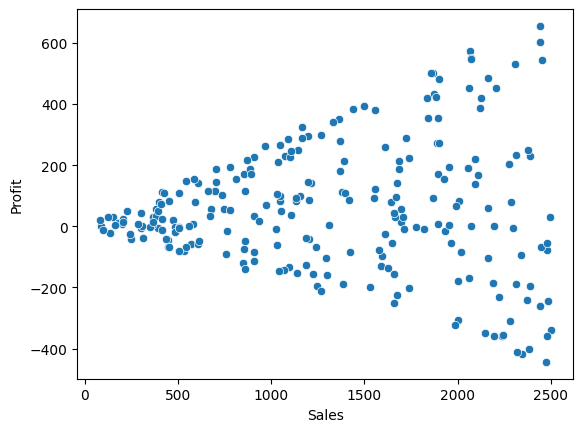

In [47]:
sns.scatterplot(data=orders,x="Sales",y="Profit")

In [48]:
#Part 4: Bonus Tasks

In [49]:
#Bonus 1 – Box Plot
#Create a Box Plot to analyze the distribution of Sales across different Categories.


Passing `hue` together with `palette` avoids the seaborn `FutureWarning`, so this is the version I keep.

<Axes: xlabel='Category', ylabel='Sales'>

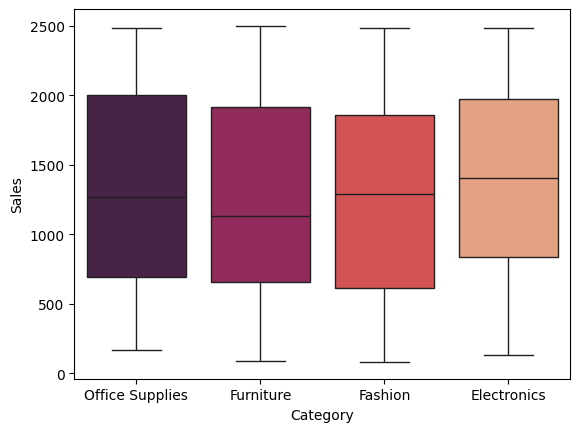

In [54]:
sns.boxplot(data=orders,x="Category",y="Sales",hue="Category",palette="rocket")

In [51]:
#Identify the Category with the highest median Sales.

In [52]:
orders.groupby('Category')['Sales'].median().idxmax()

'Electronics'

In [55]:
orders.groupby("Category")["Sales"].median()

,Sales
Category,
Electronics,1406.760
Fashion,1291.850
Furniture,1131.640
Office Supplies,1267.105


In [ ]:
#Identify any Outliers.


In [63]:
for cat,group in orders.groupby("Category"):
  q1= group["Sales"].quantile(0.25)
  q3= group["Sales"].quantile(0.75)
  iqr= q3 - q1
  outliers= group[(group["Sales"]>q3+ 1.5*iqr)| (group["Sales"]<q1-1.5*iqr)]
  print(outliers)

Empty DataFrame
Columns: [Order_ID, Order_Date, Customer_ID, City, Category, Sub-Category, Segment, Quantity, Sales, Profit]
Index: []
Empty DataFrame
Columns: [Order_ID, Order_Date, Customer_ID, City, Category, Sub-Category, Segment, Quantity, Sales, Profit]
Index: []
Empty DataFrame
Columns: [Order_ID, Order_Date, Customer_ID, City, Category, Sub-Category, Segment, Quantity, Sales, Profit]
Index: []
Empty DataFrame
Columns: [Order_ID, Order_Date, Customer_ID, City, Category, Sub-Category, Segment, Quantity, Sales, Profit]
Index: []


**Insights based on my visualization**:
1.   Electronics has the highest median Sales among all categories (1,406.76), followed by Fashion (1,291.85), Office Supplies (1,267.11), and Furniture (1,131.64). The medians are fairly close to each other, which suggests that no single category dominates in typical order value.

2.   No outliers are visible in any category, and the whiskers span a similar range, which indicates a consistent sales distribution without extreme orders.

In [64]:
#*Bonus 2 – Advanced Box Plot*


In [65]:
#Compare Profit distributions.


<Axes: xlabel='Segment', ylabel='Profit'>

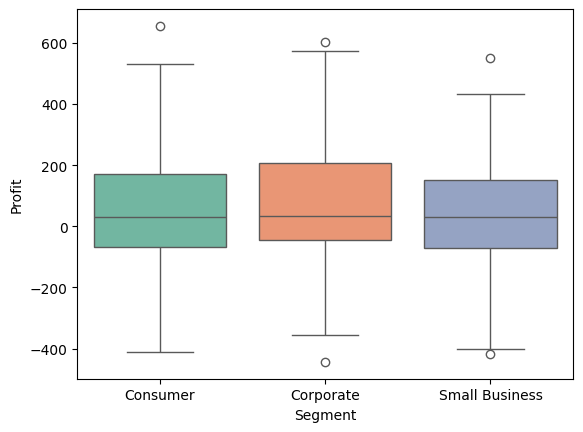

In [67]:
sns.boxplot(data=orders, x="Segment", y="Profit", hue="Segment", palette="Set2",legend=False)

In [68]:
#Identify the Segment with the highest median Profit.

In [69]:
orders.groupby("Segment")["Profit"].median().idxmax()

'Corporate'

In [70]:
#Identify any Outliers.


In [72]:
for Seg, group in orders.groupby("Segment"):
  qq1= group['Profit'].quantile(0.25)
  qq3= group["Profit"].quantile(0.75)
  iqr1= qq3- qq1
  outliers1= group[(group['Profit']> qq3 + 1.5*iqr1)| (group['Profit']< qq1 -1.5*iqr1)]
  print(outliers1)

     Order_ID              Order_Date Customer_ID   City     Category  \
174  ORD-0175 2025-09-23 00:06:01.506    CUST-045  Tanta  Electronics   

    Sub-Category   Segment  Quantity    Sales  Profit  
174  Accessories  Consumer         2  2443.53  655.43  
     Order_ID              Order_Date Customer_ID   City         Category  \
20   ORD-0021 2025-01-31 11:02:45.690    CUST-010  Tanta  Office Supplies   
105  ORD-0106 2025-06-09 21:59:29.874    CUST-074  Cairo  Office Supplies   

    Sub-Category    Segment  Quantity    Sales  Profit  
20          Pens  Corporate         3  2472.42 -443.82  
105      Binders  Corporate         3  2442.23  602.38  
     Order_ID              Order_Date Customer_ID   City         Category  \
113  ORD-0114 2025-06-22 02:24:36.151    CUST-079  Cairo  Office Supplies   
202  ORD-0203 2025-11-04 15:33:53.473    CUST-077   Giza  Office Supplies   

    Sub-Category         Segment  Quantity    Sales  Profit  
113         Pens  Small Business         3  

**Two insights based on my visualization:**

1.   Outliers in Profit appear in all three segments, mostly in orders with very high Sales (about 2,000–2,450), Some of these high-value orders resulted in losses ( -443.82 and -417.11), while others achieved the highest profits ( 655.43).

2.   Both Corporate and Small Business have one loss-making outlier each, both in the Pens sub-category (Office Supplies). This suggests high-value Pens orders may be sold with heavy discounts or high costs, and is worth investigating.

